---
title: "From Continuous Flows to Score Matching"
author: "Mark Fuge"
date: "November 9th, 2025"
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---

In the previous chapter, we explored Continuous Normalizing Flows (CNFs), where we learned a vector field $v_t$ to transform a simple base distribution into a complex data distribution. The training objective involved maximizing the log-likelihood of the data, which required computing the trace of the Jacobian of the vector field:

$$
\log p_1(x) = \log p_0(z) - \int_0^1 \text{Tr}\left(\nabla_x v_t(x(t))\right) dt
$$

While powerful, this approach has a significant computational bottleneck: the trace term $\text{Tr}(\nabla_x v_t)$. For high-dimensional data like images, computing this trace is prohibitively expensive, often requiring clever estimation tricks or restrictive model architectures that can slow down training.

This raises a critical question: **Can we define and train a generative model based on a vector field without ever needing to compute a trace?**

This chapter introduces **Score Matching**, a powerful alternative that achieves exactly this.

## Learning Objectives

By the end of this chapter, you should be able to:

1. Define the score function and be able to compute it and reason about its behavior given a density, including why it does not depend on the density's normalizing constant.
2. Explain why the Fisher divergence cannot be computed from samples and how denoising score matching turns score learning into a regression on noisy data.
3. Predict how the training noise level $\sigma$ changes the learned score field (sharp near the data versus smooth and far-reaching).
4. Explain how Langevin dynamics turns score ascent into sampling, and diagnose from samples whether the step size is too small, too large or about right.
5. Explain why Langevin sampling with a fixed noise level gets the relative weights of separated modes wrong, and why that motivates annealing (diffusion models, next chapter).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import torch
from torch import nn
import torch.optim as optim
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from gen_models_utilities import create_ring_gaussians, make_loader

# Use a consistent style
plt.style.use('seaborn-v0_8-muted')
sns.set_context('talk')

# for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = "cpu"
print(f'Using device: {device}')

Using device: cpu


## Sampling by "Climbing" the Probability Landscape

Imagine our data distribution $p_{data}(x)$ as a "probability landscape"—a mountain range where peaks correspond to likely data points (e.g., realistic images) and valleys represent unlikely ones (e.g., noise). If we were placed randomly in this landscape, how could we find (aka, generate) a "good" data point? A natural strategy would be to climb uphill. We saw this idea previously in the context of MCMC sampling, for example where Hamiltonian Monte Carlo (HMC) uses gradients to propose moves towards higher probability regions. Likewise, we will use similar ideas in Score Matching to define a generative process. Specifically, the direction of steepest ascent on the log-probability landscape is given by its gradient. This leads us to the definition of the **score function**.

### The Score Function

The score function is the gradient of the log-probability density with respect to the data $x$:

$$
s(x) \equiv \nabla_x \log p(x)
$$

This function defines a vector field where every vector points "uphill," in the direction in which the log-probability increases fastest, typically toward a nearby mode (peak) of the data distribution. If we could learn this vector field, we could invent a new generative process:

1.  Start from a random point $x_0$.
2.  Follow the score vectors to "climb" the landscape.
3.  Arrive at a peak, which corresponds to a high-likelihood data sample.


## The First Hurdle: How to Learn the Score?

Let's imagine that we want to train a neural network $s_\theta(x)$ to approximate the true data score $s_{p_{data}}(x)$. The most straightforward objective is to minimize the L2 distance between our model's score and the true score, an objective known as the **Fisher Divergence**:

$$
J(\theta) = \mathbb{E}_{x \sim p_{data}(x)} \left[ \| s_{p_{data}}(x) - s_\theta(x) \|^2 \right]
$$

However, this objective is intractable. To compute it, we need the true data score $s_{p_{data}}(x) = \nabla_x \log p_{data}(x)$. But we don't know the underlying data distribution $p_{data}(x)$; we only have samples from it. This is the central challenge of score matching.

## Solution 1: Hyvärinen's Score Matching

In 2005, Aapo Hyvärinen used techniques from partial integration to prove that the intractable Fisher Divergence objective is equivalent to a tractable one, under certain regularity conditions. The key result is:

$$
J(\theta) \propto \mathbb{E}_{x \sim p_{data}(x)} \left[ \text{Tr}\left(\nabla_x s_\theta(x)\right) + \frac{1}{2} \| s_\theta(x) \|^2 \right]
$$

What his result allowed is for us to eliminate the need for the unknown true score $s_{p_{data}}(x)$, allowing us to compute an objective using only our model $s_\theta$ and data samples $x \sim p_{data}(x)$, which we have (this is our training data).

However, look closely at the first term: $\text{Tr}(\nabla_x s_\theta(x))$[^sm-6-1]. We are right back where we started with continuous flow matching. We've traded one generative model (CNF) for another (Score Matching), but we are still stuck with the same computationally expensive trace of the Jacobian. This is why classic Score Matching wasn't a silver bullet for high-dimensional cases where CNFs struggled.

[^sm-6-1]: Note that in some texts this is referred to as $\nabla \cdot s_\theta(x)$ (the divergence of the score function) instead of $\text{Tr}(\nabla_x s_\theta(x))$, but these are mathematically equivalent.

## Solution 2: Denoising Score Matching (DSM)

The breakthrough came in 2011 from Pascal Vincent, who asked: **What if we try to learn the score of *noisy* data instead of clean data?**

To see what we might mean by this, consider the following setup:

1.  **Define a noise kernel**: We perturb our data $x$ with Gaussian noise: $p_\sigma(\tilde{x} | x) = \mathcal{N}(\tilde{x} | x, \sigma^2 I)$.
2.  **Create a noisy data distribution**: This process defines a new, noisy data distribution $p_\sigma(\tilde{x}) = \int p_\sigma(\tilde{x} | x) p_{data}(x) dx$.
3.  **Set a new goal**: Our goal is now to learn the score of this noisy distribution: $s_\theta(\tilde{x}) \approx \nabla_{\tilde{x}} \log p_\sigma(\tilde{x})$.

It turns out that the objective for this new problem, $\mathbb{E}_{p_\sigma(\tilde{x})} [\| \nabla_{\tilde{x}} \log p_\sigma(\tilde{x}) - s_\theta(\tilde{x}) \|^2]$, also simplifies, but to something much better. The optimal score model $s_\theta(\tilde{x})$, which is the thing we are trying to learn, for the Denoising objective is the one that minimizes:

$$
J_\sigma(\theta) = \mathbb{E}_{x \sim p_{data}, \tilde{x} \sim p_\sigma(\cdot|x)} \left[ \left\| s_\theta(\tilde{x}) - \nabla_{\tilde{x}} \log p_\sigma(\tilde{x} | x) \right\|^2 \right]
$$

This new target, $\nabla_{\tilde{x}} \log p_\sigma(\tilde{x} | x)$, is the score of our noise kernel, which we know analytically. Since the log-probability of our Gaussian noise kernel is:

$$
\log p_\sigma(\tilde{x} | x) = C - \frac{1}{2\sigma^2} \|\tilde{x} - x\|^2
$$

its gradient with respect to $\tilde{x}$ is simply:

$$
\nabla_{\tilde{x}} \log p_\sigma(\tilde{x} | x) = -\frac{\tilde{x} - x}{\sigma^2}
$$

We can substitute this back into our original objective:
$$
J_\sigma(\theta) = \mathbb{E}_{x \sim p_{data}, \tilde{x} \sim p_\sigma(\cdot|x)} \left[ \left\| s_\theta(\tilde{x}) + \frac{\tilde{x} - x}{\sigma^2} \right\|^2 \right]
$$

And rename $\tilde{x}$ as $x + \epsilon$, where $\epsilon \sim \mathcal{N}(0, \sigma^2 I)$, to arrive at the final, practical, **trace-free** Denoising Score Matching (DSM) loss:

$$
J_\sigma(\theta) = \mathbb{E}_{x \sim p_{data}, \epsilon \sim \mathcal{N}(0, \sigma^2 I)} \left[ \left\| s_\theta(x + \epsilon) + \frac{\epsilon}{\sigma^2} \right\|^2 \right]
$$

This is just a simple L2 regression! We train a neural network to:
1. Take a noisy sample $\tilde{x} = x + \epsilon$.
2. Predict the "ground truth" score, which is proportional to the noise that was added: $-\epsilon / \sigma^2$.

There is no trace and no intractable integrals. We have successfully found a way to learn a generative vector field that completely bypasses the CNF bottleneck. To enable this, we had to assume that we were okay with learning the score of a noisy version of the data distribution, which may seem a bit silly but, as we will see in the next chapter, this turns out to be a powerful and flexible approach for generative modeling.

## Example: Learning a Score Model for a 2D Ring of Gaussians

Let's apply this to a 2D problem to build some intuition. We'll generate data from the Ring of Gaussians we have been using in earlier chapters, and then train a neural network to learn its score function $s_\theta$ using the DSM objective. This will allow us to visualize the learned score as a vector field.

In [3]:
#| code-fold: false
#### Try changing the noise level sigma here and see
# how it affects the learned score function.
# Try values like 0.01, 0.1, 0.5, 5.0
sigma = 0.1  # Noise level
# ------------------------------------------------

# Create the dataset
data, _ = create_ring_gaussians(n_samples=5000)
loader = make_loader(data, batch_size=256)

# Define the neural network to model the score function s_theta(x)
class ScoreNet2D(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.Softplus(),
            nn.Linear(hidden, hidden),
            nn.Softplus(),
            nn.Linear(hidden, 2)
        )

    def forward(self, x):
        return self.net(x)

# Training parameters
lr = 1e-3
n_epochs = 400

# Model and optimizer
score_net = ScoreNet2D().to(device)
optimizer = optim.AdamW(score_net.parameters(), lr=lr)

# Training loop
for epoch in range(n_epochs):
    for (x,) in loader:
        x = x.to(device)
        
        # 1. Add noise
        noise = torch.randn_like(x) * sigma
        x_tilde = x + noise
        
        # 2. Predict the score
        predicted_score = score_net(x_tilde)
        
        # 3. Compute the ground truth score (target)
        target_score = -noise / (sigma**2)
        
        # 4. Calculate the DSM loss
        loss = ((predicted_score - target_score)**2).mean()
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    if epoch % 20 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

print("Training complete.")

Epoch 0, Loss: 99.9621
Epoch 20, Loss: 94.5389
Epoch 40, Loss: 96.6329
Epoch 60, Loss: 94.0892
Epoch 80, Loss: 95.9352
Epoch 100, Loss: 89.9783
Epoch 120, Loss: 91.1169
Epoch 140, Loss: 91.3176
Epoch 160, Loss: 89.9263
Epoch 180, Loss: 81.9100
Epoch 200, Loss: 96.8376
Epoch 220, Loss: 91.9254
Epoch 240, Loss: 82.5780
Epoch 260, Loss: 89.1135
Epoch 280, Loss: 78.5972
Epoch 300, Loss: 89.9539
Epoch 320, Loss: 88.9281
Epoch 340, Loss: 90.0029
Epoch 360, Loss: 81.8739
Epoch 380, Loss: 78.4657
Training complete.


Now let's visualize the learned score function as a vector field. We will overlay the score vectors on a contour plot of the target data distribution. This will show us the direction that the learned score function will push particles in.

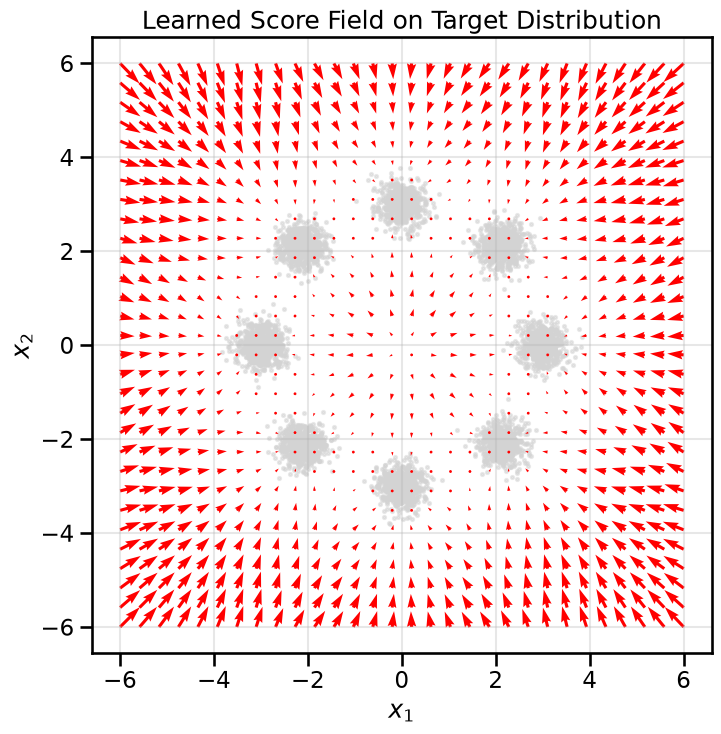

In [4]:
# Create a grid to visualize the score field
xx, yy = np.meshgrid(np.linspace(-6, 6, 30), np.linspace(-6, 6, 30))
grid_points = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32, device=device)

# Get the score at each grid point
score_net.eval()
with torch.no_grad():
    scores = score_net(grid_points).cpu().numpy()

# Plot the results
plt.figure(figsize=(8, 8))
# Plot the data distribution as a contour plot -- this can be expensive, so I'll comment it out for now
#sns.kdeplot(x=data[:, 0], y=data[:, 1], cmap="viridis", fill=True, alpha=0.7)
# Plot the original data samples as light grey dots
plt.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', alpha=0.5)


# Plot the score field
plt.quiver(grid_points[:, 0].cpu(), grid_points[:, 1].cpu(), scores[:, 0], scores[:, 1], color='red', width=0.005)
plt.title('Learned Score Field on Target Distribution')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Animation: Vector field as training progresses (DSM)
# We can set a separate sigma here for the animation
sigma_anim = sigma

# Fresh model for animation so we can see learning from scratch
score_net_anim = ScoreNet2D().to(device)
optimizer_anim = optim.AdamW(score_net_anim.parameters(), lr=1e-3)

# Grid for vector field
x_min_anim, x_max_anim, n_grid_anim = -6.0, 6.0, 25
xx_anim, yy_anim = np.meshgrid(np.linspace(x_min_anim, x_max_anim, n_grid_anim), np.linspace(x_min_anim, x_max_anim, n_grid_anim))
grid_points_anim = torch.tensor(np.stack([xx_anim.ravel(), yy_anim.ravel()], axis=1), dtype=torch.float32, device=device)

# Precompute background once
fig_anim, ax_anim = plt.subplots(figsize=(7, 7))
#sns.kdeplot(x=data[:, 0], y=data[:, 1], cmap="viridis", fill=True, alpha=0.4, ax=ax_anim)
ax_anim.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', alpha=0.5)
ax_anim.set_xlim(x_min_anim, x_max_anim)
ax_anim.set_ylim(x_min_anim, x_max_anim)
ax_anim.set_aspect('equal', adjustable='box')
ax_anim.grid(True, alpha=0.2)
ax_anim.set_title('Training the Score Field (DSM)')
ax_anim.set_xlabel('$x_1$')
ax_anim.set_ylabel('$x_2$')

# Initialize quiver (will update U,V each frame)
init_scores_anim = np.zeros_like(grid_points_anim.cpu().numpy())
# Scale down the arrows by a factor for better visibility:
Q_anim = ax_anim.quiver(grid_points_anim[:, 0].cpu(), grid_points_anim[:, 1].cpu(), 
              init_scores_anim[:, 0], init_scores_anim[:, 1],
              color='red', width=0.005, alpha=0.9)


# Training/animation parameters
n_epochs_anim = 400
capture_every_anim = 10  # capture frame every N epochs
frames_UV_anim = []
frame_labels_anim = []

# Collect frames while training
print("Training for animation…")
for epoch_anim in range(1, n_epochs_anim + 1):
    for (x_batch,) in loader:
        x_anim = x_batch.to(device)
        noise_anim = torch.randn_like(x_anim) * sigma_anim
        x_tilde_anim = x_anim + noise_anim

        pred_anim = score_net_anim(x_tilde_anim)
        target_anim = -noise_anim / (sigma_anim ** 2)
        loss_anim = ((pred_anim - target_anim) ** 2).mean()

        optimizer_anim.zero_grad()
        loss_anim.backward()
        optimizer_anim.step()

    if epoch_anim % capture_every_anim == 0 or epoch_anim == 1:
        score_net_anim.eval()
        with torch.no_grad():
            S_anim = score_net_anim(grid_points_anim).cpu().numpy()
        # Rescale S so that the largest arrows is length 1.0
        max_len_anim = np.max(np.linalg.norm(S_anim, axis=1))
        if max_len_anim > 0:
            S_anim = S_anim / max_len_anim
        frames_UV_anim.append(S_anim)
        frame_labels_anim.append(f"epoch {epoch_anim} | loss {loss_anim.item():.3f}")
        score_net_anim.train()
        
        # Optional console progress
        if epoch_anim % (capture_every_anim * 5) == 0 or epoch_anim in (1, n_epochs_anim):
            print(frame_labels_anim[-1])

# Build animation by updating quiver U,V

def init_anim():
    Q_anim.set_UVC(init_scores_anim[:, 0], init_scores_anim[:, 1])
    return (Q_anim,)

def update_anim(i):
    U_anim = frames_UV_anim[i][:, 0]
    V_anim = frames_UV_anim[i][:, 1]
    Q_anim.set_UVC(U_anim, V_anim)
    ax_anim.set_title(f'Training the Score Field (DSM) — {frame_labels_anim[i]}')
    return (Q_anim,)

ani_anim = FuncAnimation(fig_anim, update_anim, frames=len(frames_UV_anim), init_func=init_anim,
                    blit=False, interval=100, repeat=False)
plt.close(fig_anim)  # avoid static duplicate
HTML(ani_anim.to_jshtml())

Training for animation…
epoch 1 | loss 103.260
epoch 50 | loss 97.533
epoch 100 | loss 98.608
epoch 150 | loss 88.190
epoch 200 | loss 88.734
epoch 250 | loss 83.404
epoch 300 | loss 80.596
epoch 350 | loss 78.519
epoch 400 | loss 90.604


The plot shows that our network has successfully learned the score function. The learned score vectors point away from the low-density region and towards the peaks of each Gaussian, just as expected.

::: {.callout-tip appearance="default"}
### Experiment: Effect of Noise Level on Denoising Score Matching

We saw above that the key trick in Denoising Score Matching is to add noise to the data before learning the score function. The amount of noise added is controlled by the parameter $\sigma$. But what effect does the choice of $\sigma$ have on the learned score function and the quality of generated samples?

- Try changing the noise level $\sigma$ to different values (e.g., 0.01, 0.1, 0.5, 5.0). How does this affect the learned score function?
- Reflect on how Denoising Score Matching achieves its approximation compared to the original score matching objective. What effect does the noise level have on this approximation? How is this reflected in the learned score function as you vary $\sigma$? 

:::


## How do we use the learned Score Function?

Now that we have a trained model $s_\theta(x)$ that can estimate the score of a data distribution, we can finally implement our "sampling by climbing" idea. 

A naive approach would be to start from random noise and iteratively update the sample by taking small steps in the direction of the score:
$$
x_{k+1} \leftarrow x_k + \alpha s_\theta(x_k)
$$

This is just gradient ascent on the log-probability landscape defined by our score model. However, this approach has a critical flaw: it will quickly get stuck in the nearest local maximum (peak) of the distribution and fail to explore the full data distribution. So while this is OK for optimization or finding modes of the distribution, it is not sufficient for generative sampling.

Instead, we need to introduce some randomness into the process to allow exploration of the landscape. This is done using **Langevin Dynamics** which involves taking a small step in the direction of the score (the gradient ascent "climb") and then adding a small amount of noise. This noise prevents the sampler from just finding the nearest peak and stopping; instead, it allows it to explore the full distribution.

The update rule for Langevin Dynamics is:
$$
x_{k+1} \leftarrow x_k + \alpha s_\theta(x_k) + \sqrt{2\alpha} z_k
$$

where $\alpha$ is the step size and $z_k \sim \mathcal{N}(0, I)$ is standard Gaussian noise. The $s_\theta(x_k)$ term performs the climb, while the $z_k$ term makes the process stochastic, turning it into a sampler (like MCMC) rather than just an optimizer.

The choice of step size $\alpha$ is important: too large and the sampler will be unstable, too small and it will mix slowly. In practice, $\alpha$ is often decreased over time (as we will see in the next chapter) to allow for finer exploration as the sampler approaches high-density regions.

It perhaps seems magical that this simple procedure will converge to samples from the data distribution. The theoretical justification comes from the fact that Langevin Dynamics is a discretization of a continuous-time stochastic differential equation (SDE) whose stationary distribution is exactly the target distribution defined by the score function. Thus, as the number of steps goes to infinity and the step size goes to zero, the samples generated by Langevin Dynamics converge to samples from the target distribution.

Specifically, the SDE is given by:
$$
dx_t = s_\theta(x_t) dt + \sqrt{2} dW_t
$$
where $W_t$ is standard Brownian motion. We will see this connection to SDEs in more detail in the next chapter when we see its connection to Diffusion Models.


In [6]:
#| code-fold: false
# Compare deterministic gradient-ascent (no noise) vs Langevin dynamics (with noise)

def deterministic_ascent(score_model, init_points, steps=200, alpha=0.05):
    """Move points by x <- x + alpha * score(x) without noise and record trajectories."""
    x = init_points.clone().to(device)
    traj = [x.cpu().numpy()]
    score_model.eval()
    with torch.no_grad():
        for _ in range(steps):
            s = score_model(x)
            x = x + alpha * s
            traj.append(x.cpu().numpy())
    return np.array(traj)

# Langevin Dynamics Sampler for 2D
def langevin_sampler_2d(score_model, n_samples=500, n_steps=200, alpha=0.01, initial_noise_scale=5.0, track_trajectories=False, tracked_points=None):
    """Generate samples using Langevin Dynamics, with optional trajectory tracking."""
    if track_trajectories and tracked_points is not None:
        x = tracked_points.to(device)
        n_samples = tracked_points.shape[0]
    else:
        x = torch.randn(n_samples, 2, device=device) * initial_noise_scale
    
    trajectory = [x.cpu().detach().numpy()]
    
    score_model.eval()
    with torch.no_grad():
        for _ in range(n_steps):
            score = score_model(x)
            noise = torch.randn_like(x) * np.sqrt(2 * alpha)
            x = x + alpha * score + noise
            trajectory.append(x.cpu().detach().numpy())
            
    return x, np.array(trajectory)

# Choose three representative initial points to follow
init_points = torch.tensor([[ -1.0, -1.0], [ 0.0, 1.5], [ 1.0, -0.5]], dtype=torch.float32)

# Deterministic ascent trajectories (no noise)
det_traj = deterministic_ascent(score_net, init_points, steps=200, alpha=0.05)

# Langevin trajectories (with noise) using the sampler defined above
_, lang_traj = langevin_sampler_2d(score_net, track_trajectories=True, 
                                   tracked_points=init_points, n_steps=200, alpha=0.01)

# Generate a larger set of samples for density comparison
generated_samples, _ = langevin_sampler_2d(score_net, n_samples=1000, alpha=0.01)


C:\Users\mafuge\AppData\Local\Temp\ipykernel_27064\2162259831.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


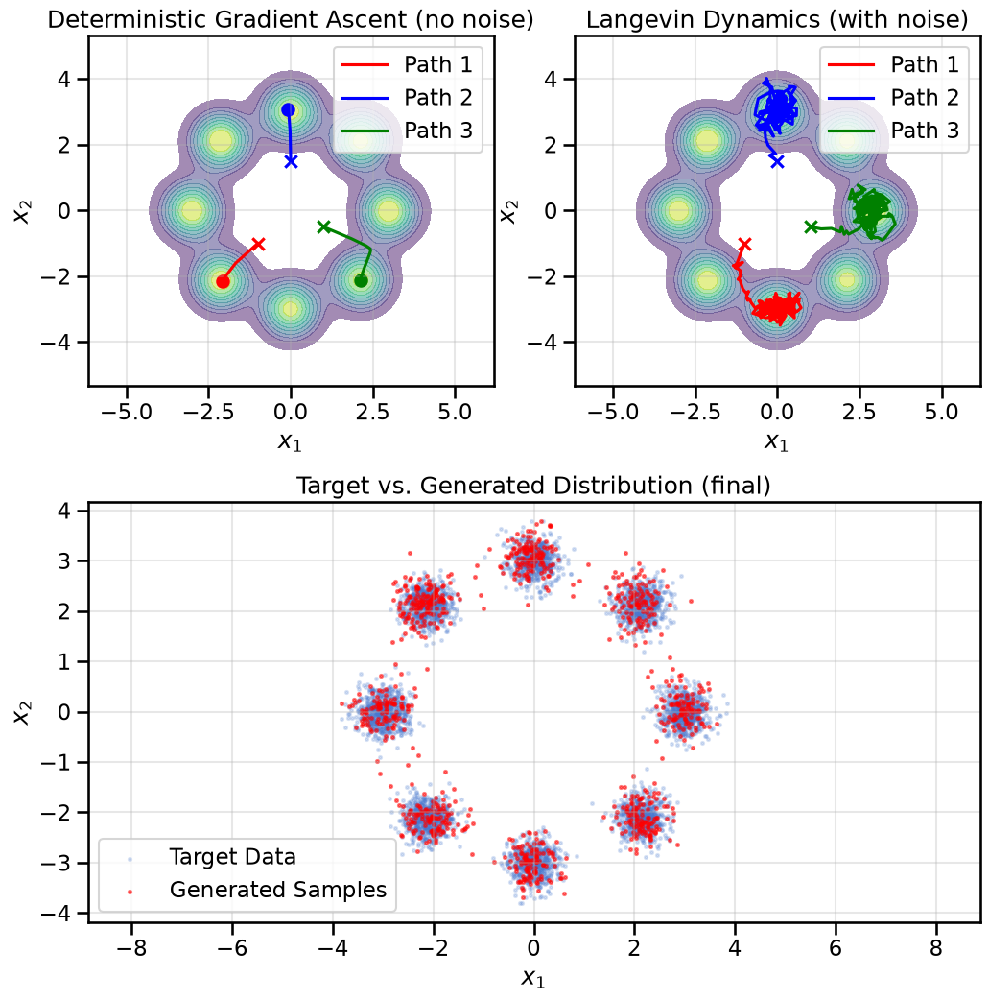

In [7]:
# Plot comparison with an additional row showing final distribution across full width
fig = plt.figure(figsize=(12, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1.2], hspace=0.3, wspace=0.2)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, :])  # span both columns for a larger final distribution plot

colors = ['red', 'blue', 'green']

# Left: deterministic ascent
ax0.set_title('Deterministic Gradient Ascent (no noise)')
sns.kdeplot(x=data[:, 0], y=data[:, 1], cmap='viridis', fill=True, alpha=0.5, ax=ax0)
for i in range(det_traj.shape[1]):
    ax0.plot(det_traj[:, i, 0], det_traj[:, i, 1], color=colors[i], label=f'Path {i+1}')
    ax0.scatter(det_traj[0, i, 0], det_traj[0, i, 1], marker='x', color=colors[i], s=80)
    ax0.scatter(det_traj[-1, i, 0], det_traj[-1, i, 1], marker='o', color=colors[i], s=80)
ax0.axis('equal')
ax0.grid(True, alpha=0.3)
ax0.legend()
ax0.set_xlabel('$x_1$')
ax0.set_ylabel('$x_2$')

# Right: Langevin dynamics
ax1.set_title('Langevin Dynamics (with noise)')
sns.kdeplot(x=data[:, 0], y=data[:, 1], cmap='viridis', fill=True, alpha=0.5, ax=ax1)
for i in range(lang_traj.shape[1]):
    ax1.plot(lang_traj[:, i, 0], lang_traj[:, i, 1], color=colors[i], label=f'Path {i+1}')
    ax1.scatter(lang_traj[0, i, 0], lang_traj[0, i, 1], marker='x', color=colors[i], s=80)
    ax1.scatter(lang_traj[-1, i, 0], lang_traj[-1, i, 1], marker='o', color=colors[i], s=80)
ax1.axis('equal')
ax1.grid(True, alpha=0.3)
ax1.legend()
ax1.set_xlabel('$x_1$')
ax1.set_ylabel('$x_2$')

# Bottom: Final distribution (full-width)
ax2.set_title('Target vs. Generated Distribution (final)')
ax2.scatter(data[:, 0], data[:, 1], s=5, alpha=0.2, label='Target Data')
ax2.scatter(generated_samples.cpu()[:, 0], generated_samples.cpu()[:, 1], s=5, alpha=0.5, color='red', label='Generated Samples')
ax2.set_xlabel('$x_1$')
ax2.set_ylabel('$x_2$')
ax2.axis('equal')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

## The Final Bridge to Diffusion Models

This works, but we have one big new problem: the distribution depends on noise level, which remains constant during both training and sampling. If we set $\sigma$ too high, the learned score will be too smooth and miss important details of the data distribution. If we set $\sigma$ too low, the score will be too noisy and hard to learn accurately. 

What if we allowed ourselves to change the noise level as a function of time during sampling? Perhaps we could start with a high noise level (large $\sigma$) to capture the broad structure of the data, and then gradually reduce the noise (small $\sigma$) to refine the samples such that they begin to resemble the true data distribution.

This is **exactly what a Diffusion Model is**: a time-conditional score model $s_\theta(x_t, t)$ that is trained via Denoising Score Matching at all noise levels $t$ simultaneously. This allows for a much more powerful and stable generative process, which we will explore in the next chapter.

## Summary and Next Steps

-   Score Matching provides a way to train a generative vector field without computing the expensive trace of the Jacobian required by CNFs.
-   The core idea is to learn the **score function** ($\nabla_x \log p(x)$), which points towards regions of high data density.
-   **Denoising Score Matching (DSM)** makes this practical by reframing the problem as a simple L2 regression: predicting the noise added to a data sample.
-   Once the score function is learned, **Langevin Dynamics** can be used to generate new data by iteratively following the score field and adding noise.
-   This framework directly leads to **Diffusion Models**, which use a time-conditional score network to reverse a gradual noising process.

## Exercises

The exercises reuse the chapter's score network, its training loop and its Langevin sampler, so run the chapter's cells first. Rough time estimates are in the titles.

Run the cell below to make the figure for Exercise 1. It draws 5000 points from a pinwheel distribution with three curved arms. Then it trains three copies of the chapter's `ScoreNet2D` on these points with the chapter's denoising score matching loss. Each copy uses a different noise level, $\sigma \in \{0.1, 0.3, 1.0\}$, and trains for 3000 steps. The cell takes about a minute and a half. Each row of the figure shows the streamlines of one learned score field $s_\theta(x)$ over the data (gray). I shuffled the rows, so they are in no particular order.

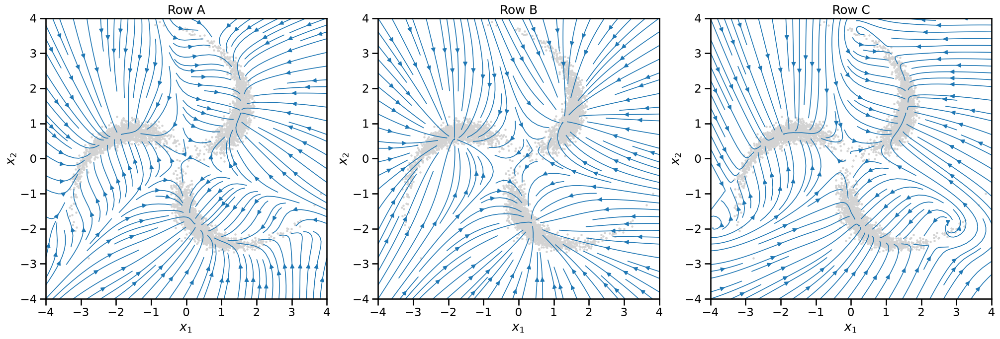

In [15]:
#| echo: false
# Figure for Exercise 1: denoising score matching on a pinwheel at three noise levels (rows shuffled)
EX_SEED = 42
EX1_SIGMAS = {'A': 0.3, 'B': 1.0, 'C': 0.1}  # row letter -> noise level used in training
EX1_STEPS = 3000  # gradient steps per network (the chapter's ring run took 400 epochs of 20 batches)


def make_pinwheel(n, rng, n_arms=3, radial_std=0.3, tangential_std=0.08, rate=0.25):
    # Pinwheel data: Gaussian blobs stretched along the radius and bent into curved arms
    arm_angles = np.linspace(0, 2 * np.pi, n_arms, endpoint=False)
    feats = rng.standard_normal((n, 2)) * [radial_std, tangential_std]
    feats[:, 0] += 1.0
    angle = arm_angles[rng.integers(n_arms, size=n)] + rate * np.exp(feats[:, 0])
    c, s = np.cos(angle), np.sin(angle)
    x = np.stack([c * feats[:, 0] - s * feats[:, 1], s * feats[:, 0] + c * feats[:, 1]], axis=1)
    return (2.0 * x).astype(np.float32)


def train_dsm(X_train, sigma_train, steps=EX1_STEPS, batch_size=256, lr=1e-3, seed=EX_SEED):
    # The chapter's DSM loss and optimizer, on random mini-batches of X_train
    torch.manual_seed(seed)
    net = ScoreNet2D().to(device)
    opt = optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps):
        x = X_train[torch.randint(0, len(X_train), (batch_size,))]
        noise = torch.randn_like(x) * sigma_train
        loss = ((net(x + noise) - (-noise / sigma_train ** 2)) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    net.eval()
    return net


X_pinwheel = torch.from_numpy(make_pinwheel(5000, np.random.default_rng(EX_SEED))).to(device)
pinwheel_nets = {letter: train_dsm(X_pinwheel, s) for letter, s in EX1_SIGMAS.items()}

pin_np = X_pinwheel.cpu().numpy()
g_fine = np.linspace(-4, 4, 160)
xx_f, yy_f = np.meshgrid(g_fine, g_fine)
grid_f = torch.tensor(np.stack([xx_f.ravel(), yy_f.ravel()], 1), dtype=torch.float32, device=device)

fig, axes = plt.subplots(1, 3, figsize=(20, 40), layout='constrained')
for ax, (letter, net) in zip(axes, pinwheel_nets.items()):
    with torch.no_grad():
        S_f = net(grid_f).cpu().numpy()
    ax.scatter(pin_np[:, 0], pin_np[:, 1], s=3, color='lightgray', zorder=0)
    ax.streamplot(xx_f, yy_f, S_f[:, 0].reshape(xx_f.shape), S_f[:, 1].reshape(xx_f.shape),
                  color='tab:blue', density=1.4, linewidth=1.2, arrowsize=1.3)
    ax.set_title(f'Row {letter}')
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 1 (~5 min): Which noise level made this field?
All three networks minimize the same denoising score matching loss

$$
J_\sigma(\theta) = \mathbb{E}_{x \sim p_{data}, \epsilon \sim \mathcal{N}(0, \sigma^2 I)} \left[ \left\| s_\theta(x + \epsilon) + \frac{\epsilon}{\sigma^2} \right\|^2 \right].
$$

The only difference between them is $\sigma$.

- (a) Match rows A, B and C to $\sigma = 0.1$, $0.3$ and $1.0$. What in each row gave it away? Why does that value of $\sigma$ give a field like this?
- (b) You want to sample the pinwheel with the chapter's `langevin_sampler_2d`. You use the settings from the chapter ($\alpha = 0.01$, 200 steps, starting points from $\mathcal{N}(0, 5^2 I)$). Which of the three networks would you use, and why? What do you give up with each choice?
- (c) The target in the loss is $-\epsilon/\sigma^2$. It always points from the noisy point $x + \epsilon$ back to the data point $x$ it came from. But the field in row B does not point to single data points. Why not? What does it point to instead?
:::

In [9]:
# You can use this code cell for this exercise, if you like.

---

Exercise 2 uses a target distribution whose score we can compute analytically (just so we don't have to train another network and also know the true answer). This is the so called "egg-carton" density

$$
p(x) \propto \exp\left( -\frac{\|x\|^2}{2 \cdot 2^2} + 2.5 \cos(2 x_1) \cos(2 x_2) \right)
$$

which is a wide Gaussian with standard deviation 2, covered by a grid of bumps. We get its score $s(x) = \nabla_x \log p(x)$ by automatic differentiation of the log density. Run the cell below to make the figure for Exercise 2. The first panel shows 2000 exact samples, drawn by rejection sampling. Panels A to D each start 2000 points from $\mathcal{N}(0, 3^2 I)$. Each panel then runs 500 steps of one of the four settings in the table of Exercise 2. The panels are in no particular order.

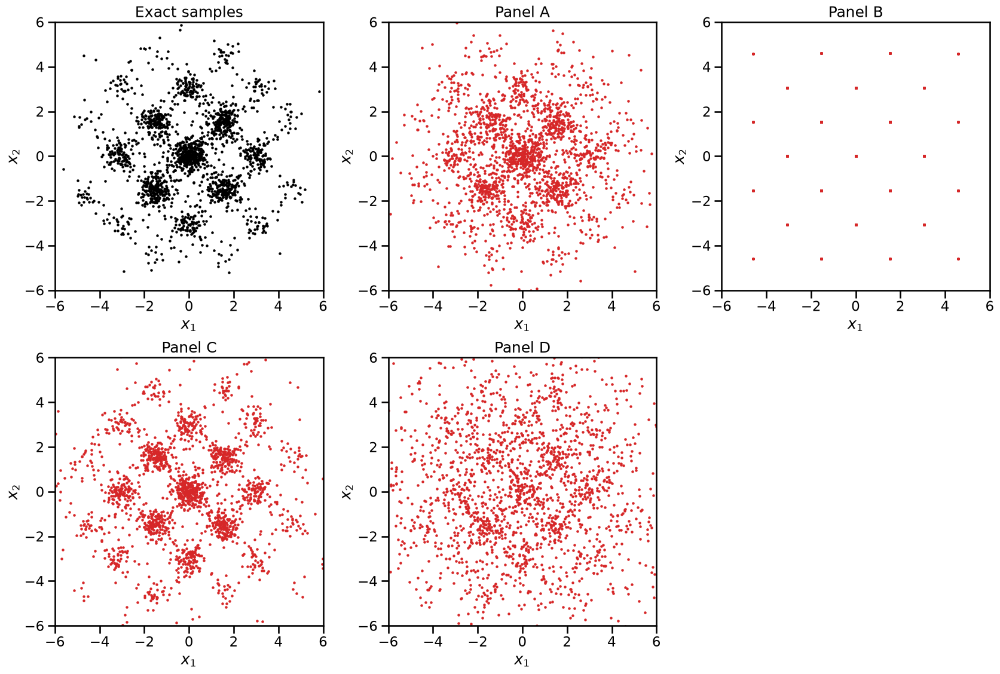

In [10]:
#| echo: false
# Figure for Exercise 2: four samplers on the egg-carton density with its exact score (panels shuffled)
EX_SEED = 42
EGG_BETA, EGG_K, EGG_STD = 2.5, 2.0, 2.0
EX2_N, EX2_STEPS = 2000, 500


def egg_log_density(x):
    # Unnormalized log density: Gaussian envelope (std 2) plus a grid of bumps
    return -0.5 * (x ** 2).sum(-1) / EGG_STD ** 2 + EGG_BETA * torch.cos(EGG_K * x[:, 0]) * torch.cos(EGG_K * x[:, 1])


def egg_score(x):
    # Exact score by automatic differentiation of the log density
    x = x.detach().requires_grad_(True)
    (grad,) = torch.autograd.grad(egg_log_density(x).sum(), x)
    return grad


def egg_exact_samples(n, seed=EX_SEED):
    # Rejection sampling from the Gaussian envelope: accept with probability exp(beta cos cos - beta)
    gen = torch.Generator().manual_seed(seed)
    out, total = [], 0
    while total < n:
        y = EGG_STD * torch.randn(20 * n, 2, generator=gen)
        accept = torch.exp(EGG_BETA * torch.cos(EGG_K * y[:, 0]) * torch.cos(EGG_K * y[:, 1]) - EGG_BETA)
        keep = y[torch.rand(len(y), generator=gen) < accept]
        out.append(keep)
        total += len(keep)
    return torch.cat(out)[:n].numpy()


def run_egg_sampler(alpha, deterministic=False, n=EX2_N, steps=EX2_STEPS, seed=EX_SEED):
    # x <- x + alpha * score(x) + sqrt(2 * alpha) * z (no noise term if deterministic), starting from N(0, 3^2 I)
    torch.manual_seed(seed)
    x = 3.0 * torch.randn(n, 2)
    for _ in range(steps):
        x = x + alpha * egg_score(x)
        if not deterministic:
            x = x + np.sqrt(2 * alpha) * torch.randn_like(x)
    return x.numpy()


egg_exact = egg_exact_samples(EX2_N)
EX2_SETTINGS = {  # panel letter -> sampler (the exercise's table maps settings to panels)
    'A': ('Langevin, alpha 0.1', dict(alpha=0.1)),
    'B': ('Ascent, alpha 0.01', dict(alpha=0.01, deterministic=True)),
    'C': ('Langevin, alpha 0.01', dict(alpha=0.01)),
    'D': ('Langevin, alpha 0.0001', dict(alpha=1e-4)),
}
egg_panels = {letter: run_egg_sampler(**kw) for letter, (name, kw) in EX2_SETTINGS.items()}

fig, axes = plt.subplots(2, 3, figsize=(17, 11.5))
axes[-1, -1].axis('off')  # five panels on a 2 x 3 grid
panels = [('Exact samples', egg_exact)] + [(f'Panel {letter}', x) for letter, x in egg_panels.items()]
for ax, (title, x) in zip(axes.ravel(), panels):
    ax.scatter(x[:, 0], x[:, 1], s=3, color='k' if title == 'Exact samples' else 'tab:red')
    ax.set_title(title)
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 2 (~5 min): Which sampler made these samples?
Every setting uses the exact score $s(x)$. Settings 2 to 4 draw fresh noise $z_k \sim \mathcal{N}(0, I)$ at every step.

| Setting | Update rule | Step size $\alpha$ | Panel |
|---|---|---|---|
| 1 | $x_{k+1} = x_k + \alpha s(x_k)$ | 0.01 | ? |
| 2 | $x_{k+1} = x_k + \alpha s(x_k) + \sqrt{2\alpha}\, z_k$ | 0.0001 | ? |
| 3 | $x_{k+1} = x_k + \alpha s(x_k) + \sqrt{2\alpha}\, z_k$ | 0.01 | ? |
| 4 | $x_{k+1} = x_k + \alpha s(x_k) + \sqrt{2\alpha}\, z_k$ | 0.1 | ? |

Replace each ? with the letter of the panel that the setting made. For each match, what in the panel gave it away? Why does that setting give this result?
:::

---

Exercise 3 moves to one dimension, where you can follow every step. The target is a mixture of a wide and a narrow Gaussian,

$$
p(x) = \frac{0.7}{0.6\sqrt{2\pi}} \exp\left( -\frac{(x + 2)^2}{2 \cdot 0.6^2} \right) + \frac{0.3}{0.25\sqrt{2\pi}} \exp\left( -\frac{(x - 2)^2}{2 \cdot 0.25^2} \right),
$$

and we can compute its score exactly. Run the cell below. It makes two figures and a table. The first figure shows $p(x)$ and its score $s(x) = \frac{d}{dx} \log p(x)$. In the second figure, each row starts 5000 points from $\mathcal{N}(0, 3^2)$ and runs 1000 steps. The first row uses deterministic ascent with $\alpha = 0.01$. The other rows use Langevin dynamics with $\alpha = 0.001$, $0.01$ and $0.1$. The first four columns show histograms of the points after 0, 10, 100 and 1000 steps, with $p(x)$ in black. The last column shows the paths of 15 of the points. The table gives the share of points to the right of the density minimum between the two modes.

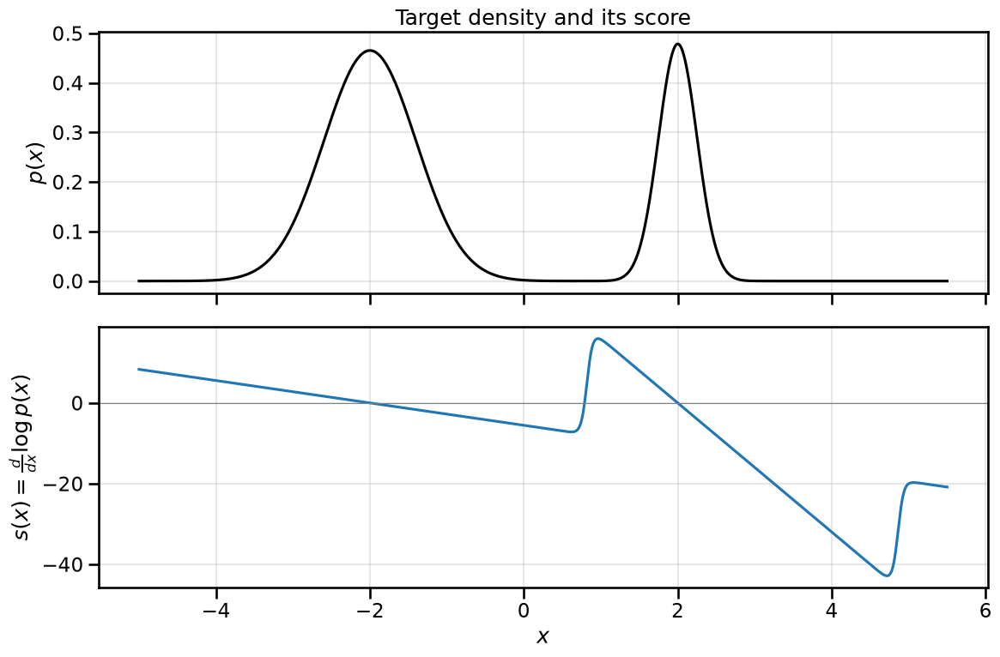

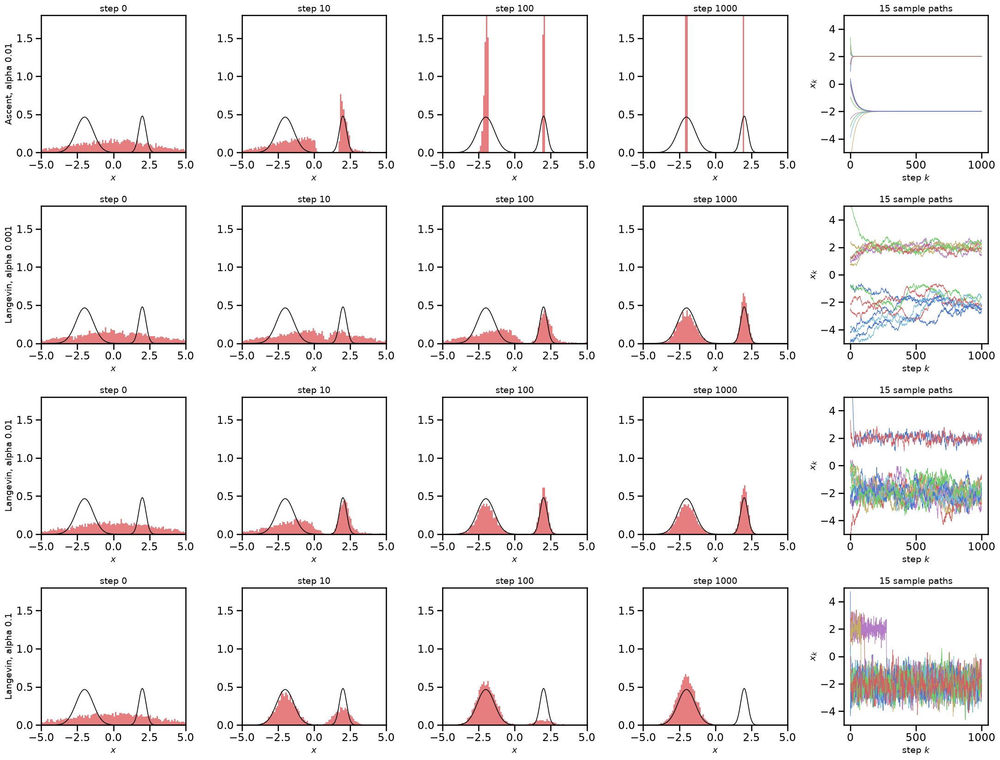

Share of points right of the density minimum at x = 0.79 (target: 0.30)
                             step 0    step 10   step 100  step 1000
Ascent, alpha 0.01             0.39       0.39       0.39       0.39
Langevin, alpha 0.001          0.39       0.39       0.40       0.40
Langevin, alpha 0.01           0.40       0.41       0.41       0.41
Langevin, alpha 0.1            0.40       0.30       0.10       0.00


In [11]:
#| echo: false
# Figures for Exercise 3: a 1D two-mode mixture, its exact score, and four samplers step by step
EX_SEED = 42
from math import erf

MIX_W = np.array([0.7, 0.3])
MIX_MU = np.array([-2.0, 2.0])
MIX_SD = np.array([0.6, 0.25])
EX3_N, EX3_STEPS, EX3_SNAPS, EX3_PATHS = 5000, 1000, [0, 10, 100, 1000], 15


def mix_components(x):
    # Weighted component densities, one column per mode
    return MIX_W * np.exp(-0.5 * ((x[:, None] - MIX_MU) / MIX_SD) ** 2) / (MIX_SD * np.sqrt(2 * np.pi))


def mix_pdf(x):
    return mix_components(x).sum(axis=1)


def mix_score(x):
    # d/dx log p(x): each mode's score -(x - mu)/sd^2, weighted by that mode's share of p(x)
    c = mix_components(x)
    resp = c / c.sum(axis=1, keepdims=True)
    return (resp * (-(x[:, None] - MIX_MU) / MIX_SD ** 2)).sum(axis=1)


xs_1d = np.linspace(-5, 5.5, 2101)
x_dip = xs_1d[(xs_1d > -1.5) & (xs_1d < 1.5)][np.argmin(mix_pdf(xs_1d[(xs_1d > -1.5) & (xs_1d < 1.5)]))]  # density minimum between the modes

fig, (ax_p, ax_s) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax_p.plot(xs_1d, mix_pdf(xs_1d), color='k')
ax_p.set_ylabel('$p(x)$')
ax_p.set_title('Target density and its score')
ax_s.plot(xs_1d, mix_score(xs_1d), color='tab:blue')
ax_s.axhline(0, color='0.5', linewidth=0.8)
ax_s.set_ylabel(r'$s(x) = \frac{d}{dx} \log p(x)$')
ax_s.set_xlabel('$x$')
for ax in (ax_p, ax_s):
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

EX3_SETTINGS = [('Ascent, alpha 0.01', 0.01, False), ('Langevin, alpha 0.001', 0.001, True),
                ('Langevin, alpha 0.01', 0.01, True), ('Langevin, alpha 0.1', 0.1, True)]
rng_ex3 = np.random.default_rng(EX_SEED)
ex3_snaps, ex3_paths, ex3_right_share = {}, {}, {}
for name, a, noisy in EX3_SETTINGS:
    x = rng_ex3.normal(0.0, 3.0, EX3_N)
    snaps, paths, share = {0: x.copy()}, [x[:EX3_PATHS].copy()], [np.mean(x > x_dip)]
    for k in range(1, EX3_STEPS + 1):
        x = x + a * mix_score(x)
        if noisy:
            x = x + np.sqrt(2 * a) * rng_ex3.standard_normal(EX3_N)
        paths.append(x[:EX3_PATHS].copy())
        share.append(np.mean(x > x_dip))
        if k in EX3_SNAPS:
            snaps[k] = x.copy()
    ex3_snaps[name], ex3_paths[name], ex3_right_share[name] = snaps, np.array(paths), np.array(share)

fig, axes = plt.subplots(len(EX3_SETTINGS), len(EX3_SNAPS) + 1, figsize=(22, 4.2 * len(EX3_SETTINGS)))
bins_1d = np.linspace(-5, 5, 101)
for r, (name, a, noisy) in enumerate(EX3_SETTINGS):
    for c, k in enumerate(EX3_SNAPS):
        ax = axes[r, c]
        ax.hist(ex3_snaps[name][k], bins=bins_1d, density=True, color='tab:red', alpha=0.6)
        ax.plot(xs_1d, mix_pdf(xs_1d), color='k', linewidth=1.2)
        ax.set_xlim(-5, 5)
        ax.set_ylim(0, 1.8)
        ax.set_title(f'step {k}', fontsize=14)
        ax.set_xlabel('$x$', fontsize=14)
    axes[r, 0].set_ylabel(name, fontsize=14)
    ax = axes[r, -1]
    ax.plot(ex3_paths[name], linewidth=0.8)
    ax.set_ylim(-5, 5)
    ax.set_title(f'{EX3_PATHS} sample paths', fontsize=14)
    ax.set_xlabel('step $k$', fontsize=14)
    ax.set_ylabel('$x_k$', fontsize=14)
plt.tight_layout()
plt.show()

target_right_share = sum(w * 0.5 * (1 - erf((x_dip - m) / (s * np.sqrt(2)))) for w, m, s in zip(MIX_W, MIX_MU, MIX_SD))
print(f'Share of points right of the density minimum at x = {x_dip:.2f} (target: {target_right_share:.2f})')
print(f"{'':24s}" + ''.join(f'{f"step {k}":>11s}' for k in EX3_SNAPS))
for name, a, noisy in EX3_SETTINGS:
    print(f'{name:24s}' + ''.join(f'{ex3_right_share[name][k]:11.2f}' for k in EX3_SNAPS))

::: {.callout-note appearance="simple" icon=false}
### Exercise 3 (~10 min): Langevin step by step in 1D
- (a) Look at the score in the first figure. Where is it zero, and why there? Why is it so much steeper around the right mode than around the left one? One point sits at $x = 0.5$ and another at $x = 1.5$. Which way does each one move on its next step? Why do they move in opposite directions when they are only 1 unit apart?
- (b) Describe what each row of the second figure does over the 1000 steps. Why does each row do this, given its update rule and step size?
- (c) With $\alpha = 0.01$, both modes have the right shape after 100 steps. But about 41% of the points sit in the right mode instead of 30%. Why? What would it take to change the split, and why?
- (d) The chapter ends by proposing to change the noise level during sampling. What does a large $\sigma$ do to the score between the two modes? What does it do to the 70/30 weights? Why do these two effects together fix the split in (c)?
- (e) (Optional) Far to the right of both modes, near $x \approx 4.8$, the score jumps upward again. Why?
:::

---

Exercise 4 returns to the chapter's sampler, `langevin_sampler_2d`, which produced the ring samples with $\alpha = 0.01$. Its loop is

```python
for _ in range(n_steps):
    score = score_model(x)
    noise = torch.randn_like(x) * np.sqrt(2 * alpha)
    x = x + alpha * score + noise
```

The cell below applies it to a narrow valley: a Gaussian with standard deviation 2 along the valley and 0.06 across it, rotated by $-30^\circ$,

$$
p(x) \propto \exp\left( -\frac{u^2}{2 \cdot 2^2} - \frac{v^2}{2 \cdot 0.06^2} \right),
$$

where $u$ and $v$ are the coordinates of $x$ along and across the valley. `ValleyScore` returns the exact score of this density, so no network is involved. The cell runs the sampler four times: first exactly as in the chapter, then with other step sizes and numbers of steps. Run it and the plotting cell after it, which draws the samples of each run over exact samples of the valley (gray).

In [12]:
EX_SEED = 42  # seed for the exercise runs


class ValleyScore(nn.Module):
    """Exact score of a narrow Gaussian valley: std 2 along it, 0.06 across it, rotated by -30 degrees."""

    def __init__(self, std_along=2.0, std_across=0.06, angle_deg=-30.0):
        super().__init__()
        angle = np.deg2rad(angle_deg)
        self.along = torch.tensor([np.cos(angle), np.sin(angle)], dtype=torch.float32)    # unit vector along the valley
        self.across = torch.tensor([-np.sin(angle), np.cos(angle)], dtype=torch.float32)  # unit vector across it
        self.std_along, self.std_across = std_along, std_across

    def forward(self, x):
        u = x @ self.along   # coordinate along the valley
        v = x @ self.across  # coordinate across the valley
        return -(u / self.std_along ** 2)[:, None] * self.along - (v / self.std_across ** 2)[:, None] * self.across


valley_score = ValleyScore()

# Run 1: the chapter's call, unchanged (alpha = 0.01, 200 steps, start from N(0, 5^2 I))
torch.manual_seed(EX_SEED)
valley_run1, _ = langevin_sampler_2d(valley_score, n_samples=1000, alpha=0.01)

# Run 2: a smaller step size
torch.manual_seed(EX_SEED)
valley_run2, _ = langevin_sampler_2d(valley_score, n_samples=1000, n_steps=500, alpha=0.007)

# Runs 3 and 4: a much smaller step size, for 500 and for 5000 steps
torch.manual_seed(EX_SEED)
valley_run3, _ = langevin_sampler_2d(valley_score, n_samples=1000, n_steps=500, alpha=0.001)
torch.manual_seed(EX_SEED)
valley_run4, _ = langevin_sampler_2d(valley_score, n_samples=1000, n_steps=5000, alpha=0.001)

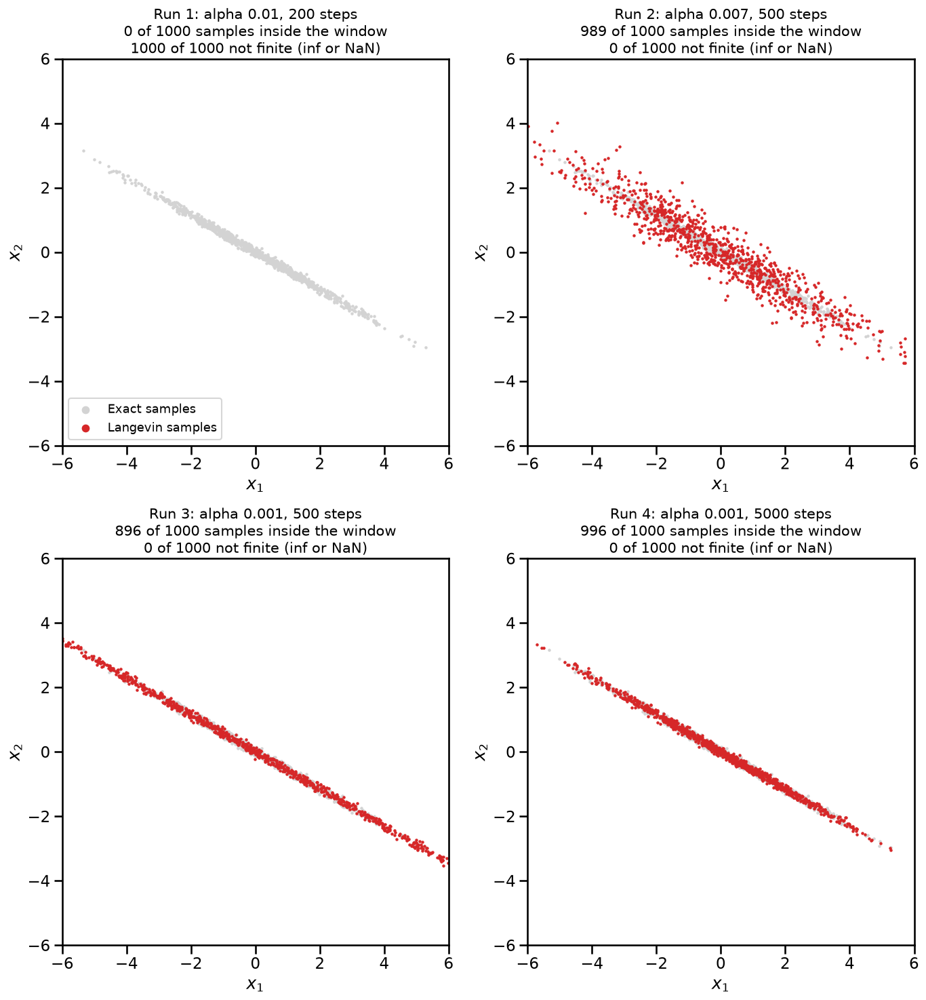

In [13]:
#| echo: false
# Figure for Exercise 4: the four runs over exact samples of the valley
torch.manual_seed(EX_SEED)
valley_exact = (2.0 * torch.randn(1000, 1) * valley_score.along + 0.06 * torch.randn(1000, 1) * valley_score.across).numpy()
valley_runs = {'Run 1: alpha 0.01, 200 steps': valley_run1, 'Run 2: alpha 0.007, 500 steps': valley_run2,
               'Run 3: alpha 0.001, 500 steps': valley_run3, 'Run 4: alpha 0.001, 5000 steps': valley_run4}
VALLEY_LIM = 6.0
fig, axes = plt.subplots(2, 2, figsize=(14, 15))
for ax, (title, x) in zip(axes.ravel(), valley_runs.items()):
    x = x.cpu().numpy()
    finite = np.isfinite(x).all(axis=1)
    inside = finite & (np.abs(x) < VALLEY_LIM).all(axis=1)
    ax.scatter(valley_exact[:, 0], valley_exact[:, 1], s=3, color='lightgray', label='Exact samples')
    ax.scatter(x[inside, 0], x[inside, 1], s=3, color='tab:red', label='Langevin samples')
    ax.set_title(f'{title}\n{inside.sum()} of {len(x)} samples inside the window\n'
                 f'{(~finite).sum()} of {len(x)} not finite (inf or NaN)', fontsize=15)
    ax.set_xlim(-VALLEY_LIM, VALLEY_LIM)
    ax.set_ylim(-VALLEY_LIM, VALLEY_LIM)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
axes[0, 0].legend(loc='lower left', fontsize=13, markerscale=4)
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 4 (~7 min): What went wrong with the sampler that worked on the ring?
All four runs finished without an error message.

- (a) What went wrong in run 1, which uses the chapter's settings? Why did a step size that worked on the ring fail on this target?
- (b) What is wrong with the samples of run 2? Why does a step size only 30% smaller than in run 1 give such a different result?
- (c) Runs 3 and 4 use $\alpha = 0.001$. What is still wrong after 500 steps, and why does it take so many more steps to fix?
- (d) Which settings would you use for this target, and what do they cost compared with the ring? Why?
:::

In [14]:
# You can use this code cell for this exercise, if you like.

---

::: {.callout-note appearance="simple" icon=false}
### Exercise 5 (~10 min): Why the valley diverges (optional take-home)
Across the valley of Exercise 4, the target is a one-dimensional Gaussian with standard deviation $s = 0.06$, and its score is $-v/s^2$.

- (a) Without the noise term, one Langevin step is $v_{k+1} = (1 - \alpha/s^2)\, v_k$. For which $\alpha$ does $|v|$ grow from step to step instead of shrinking? Why does adding the noise term not rescue it? Compare your limit with runs 1 and 2 of Exercise 4.
- (b) With the noise term, the variance of $v$ follows $\mathrm{Var}_{k+1} = (1 - \alpha/s^2)^2\, \mathrm{Var}_k + 2\alpha$. Which variance does it settle at, and how does that compare with $s^2$? Does it explain the width of run 2 across the valley? Why does the error grow as $\alpha$ approaches the limit from (a)?
- (c) Without noise, the update is the explicit Euler method for $\dot{x} = s(x)$. Where have you met the same step size limit when simulating a mechanical system, and why does a target with one narrow and one wide direction behave like a stiff system? What does that mean for the number of Langevin steps?
:::